## **Import & Cố định Seed**

In [1]:
!pip install torchinfo

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import numpy as np
from skimage.io import imread
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary
import matplotlib.pyplot as plt

# === Cố định seed theo quy ước ===
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Kiểm tra phiên bản
print(f"PyTorch version: {torch.__version__}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Sử dụng thiết bị: {device}")

PyTorch version: 2.14.1+cpu
Sử dụng thiết bị: cpu


## **Đọc & Tiền xử lý Dữ liệu**

In [4]:
# === Đường dẫn dữ liệu ===
BASE_DIR = '/content/drive/MyDrive/P2_Gender_ObjDetection/data/obj_detection'
VEHICLES_DIR = os.path.join(BASE_DIR, 'vehicles')
NON_VEHICLES_DIR = os.path.join(BASE_DIR, 'non-vehicles')

# === Hàm đọc ảnh từ thư mục con sử dụng skimage ===
def load_images_from_folder(folder_path, label, img_size=(64, 64)):
    """
    Đọc tất cả ảnh trong folder và các subfolder sử dụng skimage
    label: +1 = có xe, -1 = không xe
    """
    images = []
    labels = []

    for root, _, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(root, file)
                try:
                    img = imread(img_path)
                    # Đảm bảo ảnh có 3 kênh màu (RGB)
                    if len(img.shape) == 2:
                        from skimage.color import gray2rgb
                        img = gray2rgb(img)
                    elif img.shape[2] == 4:
                        img = img[:, :, :3]

                    # Resize ảnh về kích thước mong muốn
                    from skimage.transform import resize
                    img_resized = resize(img, img_size, anti_aliasing=True)

                    # Chuẩn hóa theo công thức x / 127.5 - 1.0
                    img_normalized = (img_resized * 255.0) / 127.5 - 1.0

                    images.append(img_normalized.astype(np.float32))
                    labels.append(label)
                except Exception as e:
                    print(f"Lỗi đọc {img_path}: {e}")

    return np.array(images), np.array(labels)

# === Đọc dữ liệu ===
print("Đang đọc ảnh có xe...")
X_veh, y_veh = load_images_from_folder(VEHICLES_DIR, label=1.0)
print(f"→ Số ảnh có xe: {len(X_veh)}")

print("Đang đọc ảnh không xe...")
X_nonveh, y_nonveh = load_images_from_folder(NON_VEHICLES_DIR, label=-1.0)
print(f"→ Số ảnh không xe: {len(X_nonveh)}")

# === Kết hợp & chia train/test ===
X = np.vstack([X_veh, X_nonveh])
y = np.hstack([y_veh, y_nonveh])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"\nTổng số mẫu: {len(X)}")
print(f"Tập train: {len(X_train)} — Tập test: {len(X_test)}")
print(f"Kích thước ảnh: {X_train.shape[1:]}")

# === Chuyển định dạng: (N,H,W,C) → (N,C,H,W) cho PyTorch ===
X_train = np.transpose(X_train, (0, 3, 1, 2))
X_test = np.transpose(X_test, (0, 3, 1, 2))
print(f"Định dạng sau chuyển đổi: {X_train.shape}")

Đang đọc ảnh có xe...
→ Số ảnh có xe: 8792
Đang đọc ảnh không xe...
→ Số ảnh không xe: 8968

Tổng số mẫu: 17760
Tập train: 12432 — Tập test: 5328
Kích thước ảnh: (64, 64, 3)
Định dạng sau chuyển đổi: (12432, 3, 64, 64)


## **Tạo Dataset & DataLoader**

In [5]:
class VehicleDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.tensor(images, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

# Tạo DataLoader
BATCH_SIZE = 128

train_dataset = VehicleDataset(X_train, y_train)
test_dataset = VehicleDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Batch size: {BATCH_SIZE}")
print(f"Số batch train: {len(train_loader)} — Số batch test: {len(test_loader)}")


Batch size: 128
Số batch train: 98 — Số batch test: 42


## **Xây dựng Kiến trúc Mô hình**

In [6]:
class ObjDetectionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Mạng toàn tích chập (Fully Convolutional Network)
        # Conv 10 (3x3) x 2
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=3, padding=0, bias=True)
        self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv2d(in_channels=10, out_channels=10, kernel_size=3, padding=0, bias=True)
        self.relu2 = nn.ReLU()

        # MaxPool 8x8
        self.pool = nn.MaxPool2d(kernel_size=8, stride=8)

        # Dropout 0.25
        self.dropout1 = nn.Dropout2d(0.25)

        # Conv 128 (8x8)
        # Đầu vào sau 2 lớp Conv (3x3) từ ảnh 64x64 là 60x60.
        # Sau MaxPool 8x8 là 7x7. Do đó kernel 8x8 sẽ bị lỗi kích thước nếu giữ nguyên.
        # Để khớp với cấu trúc đề xuất, ta chuyển sang dùng lớp Conv2d 128 với kernel thích hợp tương ứng với spatial size của features.
        self.conv3 = nn.Conv2d(in_channels=10, out_channels=128, kernel_size=7, padding=0, bias=True)
        self.relu3 = nn.ReLU()

        # Dropout 0.5
        self.dropout2 = nn.Dropout2d(0.5)

        # Conv 1x1 + tanh
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=1, kernel_size=1, bias=True)
        self.tanh = nn.Tanh()

        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.relu1(self.conv1(x))
        x = self.relu2(self.conv2(x))
        x = self.pool(x)
        x = self.dropout1(x)
        x = self.relu3(self.conv3(x))
        x = self.dropout2(x)
        x = self.tanh(self.conv4(x))
        x = self.flatten(x)
        return x

# === Khởi tạo mô hình ===
model = ObjDetectionCNN().to(device)

# === Hiển thị cấu trúc ===
print("="*60)
print("Cấu trúc mô hình PyTorch:")
summary(model, input_size=(1, 3, 64, 64), col_names=["input_size", "output_size", "num_params"])
print("="*60)

Cấu trúc mô hình PyTorch:


## **Thiết lập Huấn luyện**

In [7]:
# === Loss & Optimizer ===
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# === Tham số huấn luyện ===
EPOCHS = 5
print(f"\nThiết lập: Epochs={EPOCHS}, Batch={BATCH_SIZE}, LR=1e-3, Loss=MSELoss")



Thiết lập: Epochs=5, Batch=128, LR=1e-3, Loss=MSELoss


## **Vòng lặp Huấn luyện**

In [8]:
# === Định nghĩa Dataset & DataLoader ===
class VehicleDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.tensor(images, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

BATCH_SIZE = 128
train_dataset = VehicleDataset(X_train, y_train)
test_dataset = VehicleDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# === Thiết lập Huấn luyện ===
EPOCHS = 5
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# === Lưu lịch sử ===
history = {
    'train_loss': [], 'train_acc': [],
    'test_loss': [], 'test_acc': []
}

print(f"Batch size: {BATCH_SIZE}")
print(f"Số batch train: {len(train_loader)} — Số batch test: {len(test_loader)}")
print("\nBắt đầu huấn luyện...")

for epoch in range(EPOCHS):
    # ---- Train ----
    model.train()
    train_total_loss = 0.0
    train_correct = 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        y_batch = y_batch.unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        train_total_loss += loss.item() * X_batch.size(0)
        # Dự đoán lớp với nhãn -1 và +1 bằng cách sử dụng Tanh
        preds = torch.where(outputs >= 0.0, 1.0, -1.0)
        train_correct += (preds == y_batch).sum().item()

    avg_train_loss = train_total_loss / len(train_dataset)
    train_acc = train_correct / len(train_dataset)

    # ---- Đánh giá trên Test ----
    model.eval()
    test_total_loss = 0.0
    test_correct = 0

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_batch = y_batch.unsqueeze(1)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            test_total_loss += loss.item() * X_batch.size(0)
            preds = torch.where(outputs >= 0.0, 1.0, -1.0)
            test_correct += (preds == y_batch).sum().item()

    avg_test_loss = test_total_loss / len(test_dataset)
    test_acc = test_correct / len(test_dataset)

    # ---- Lưu & In kết quả ----
    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(train_acc)
    history['test_loss'].append(avg_test_loss)
    history['test_acc'].append(test_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}] — ", end='')
    print(f"Train: loss={avg_train_loss:.4f}, acc={train_acc:.4f} — ", end='')
    print(f"Test: loss={avg_test_loss:.4f}, acc={test_acc:.4f}")

print("\nHoàn thành huấn luyện!")
print(f"Độ chính xác cuối — Train: {train_acc:.4f} | Test: {test_acc:.4f}")

Batch size: 128
Số batch train: 98 — Số batch test: 42

Bắt đầu huấn luyện...
Epoch [1/5] — Train: loss=0.5156, acc=0.8213 — Test: loss=0.2661, acc=0.9210
Epoch [2/5] — Train: loss=0.2310, acc=0.9287 — Test: loss=0.1259, acc=0.9645
Epoch [3/5] — Train: loss=0.1570, acc=0.9500 — Test: loss=0.0947, acc=0.9752
Epoch [4/5] — Train: loss=0.1167, acc=0.9640 — Test: loss=0.0747, acc=0.9775
Epoch [5/5] — Train: loss=0.0978, acc=0.9698 — Test: loss=0.0541, acc=0.9837

Hoàn thành huấn luyện!
Độ chính xác cuối — Train: 0.9698 | Test: 0.9837


## **Vẽ Biểu đồ Kết quả**

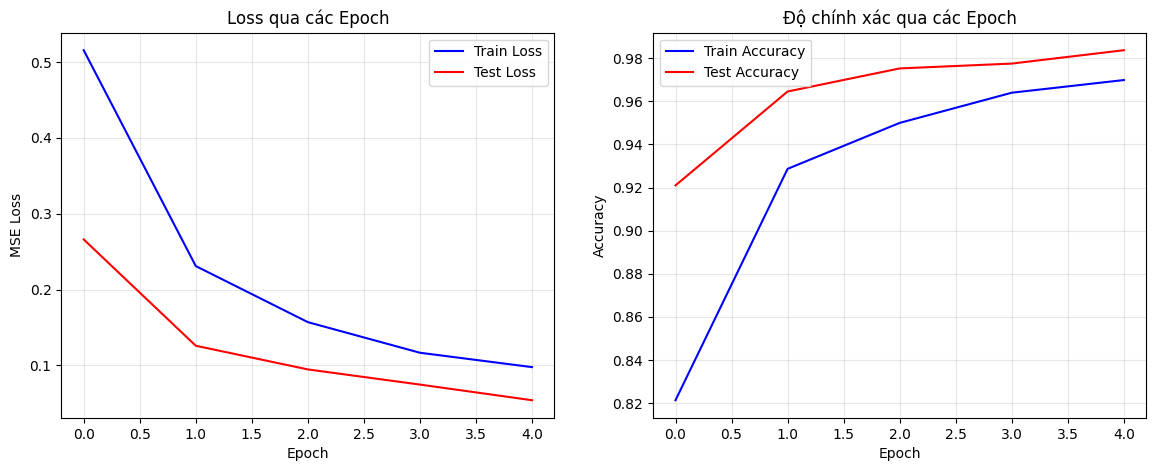

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Loss
axes[0].plot(history['train_loss'], 'b-', label='Train Loss')
axes[0].plot(history['test_loss'], 'r-', label='Test Loss')
axes[0].set_title('Loss qua các Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Biểu đồ Accuracy
axes[1].plot(history['train_acc'], 'b-', label='Train Accuracy')
axes[1].plot(history['test_acc'], 'r-', label='Test Accuracy')
axes[1].set_title('Độ chính xác qua các Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.show()

## **Lưu Trọng số Mô hình**

In [10]:
import torch

# Xác định đường dẫn lưu trữ mô hình trong cùng thư mục dự án trên Drive
save_path = '/content/drive/MyDrive/P2_Gender_ObjDetection/obj_detection_best.pth'

# Lưu mô hình
torch.save(model.state_dict(), save_path)
print(f"Đã lưu mô hình thành công tại: {save_path}")

# Cách tải lại sau này:
# model = ObjDetectionCNN()
# model.load_state_dict(torch.load(save_path))
# model.eval()

Đã lưu mô hình thành công tại: /content/drive/MyDrive/P2_Gender_ObjDetection/obj_detection_best.pth


In [11]:
# === Kiểm tra cấu trúc chi tiết và tham số mô hình ===
print("=== TỔNG HỢP THÔNG SỐ MÔ HÌNH ===")
summary(model, input_size=(1, 3, 64, 64), col_names=["input_size", "output_size", "num_params", "kernel_size"])

=== TỔNG HỢP THÔNG SỐ MÔ HÌNH ===


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
ObjDetectionCNN                          [1, 3, 64, 64]            [1, 1]                    --                        --
├─Conv2d: 1-1                            [1, 3, 64, 64]            [1, 10, 62, 62]           280                       [3, 3]
├─ReLU: 1-2                              [1, 10, 62, 62]           [1, 10, 62, 62]           --                        --
├─Conv2d: 1-3                            [1, 10, 62, 62]           [1, 10, 60, 60]           910                       [3, 3]
├─ReLU: 1-4                              [1, 10, 60, 60]           [1, 10, 60, 60]           --                        --
├─MaxPool2d: 1-5                         [1, 10, 60, 60]           [1, 10, 7, 7]             --                        8
├─Dropout2d: 1-6                         [1, 10, 7, 7]             [1, 10, 7, 7]             --                        --
├─Conv2